# Лабораторная работа 4. ML-модель в production

Беру карточки ДТП из первой работы и оцениваю вероятность погибших в уже произошедшем ДТП.
Использую время, координаты, погоду, освещение и число машин. Число погибших и раненых в признаки не включаю.
Это оценка тяжести по известным условиям аварии, а не прогноз числа будущих ДТП из hotspot-ai.

Код обучения и Feast — в [pipeline.py](pipeline.py), REST-сервис — в [serving.py](serving.py),
мониторинг — в [monitoring.py](monitoring.py), опыт с сенсором — в [sensor.py](sensor.py).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'lab_04').is_dir() and (p / 'requirements.txt').exists())
sys.path.insert(0, str(ROOT))
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
os.environ['FEAST_TELEMETRY'] = 'False'
WORK = ROOT / '_work/lab04'
WORK.mkdir(parents=True, exist_ok=True)
from lab_04.pipeline import FEATURES, prepare, feature_store, fit_models, compare_online, model_latency
from lab_04.serving import test_service
from lab_04.monitoring import monitor
from lab_04.sensor import experiment
import mlflow
print('Рабочая папка:', WORK)

Рабочая папка: C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Данные и сравнение моделей

Беру 2025 год и три региона из ЛР-3. Обучаю на январе–августе, выбираю модель на сентябре–октябре,
а ноябрь–декабрь оставляю для итоговой оценки. Положительный класс редкий, поэтому основная метрика — PR-AUC.
Accuracy и F1 показываю вместе с ней: высокая accuracy сама по себе здесь ничего не доказывает.

,выборка,ДТП,с погибшими,доля
0,train,8959,345,0.038509
1,valid,2788,133,0.047704
2,test,2515,124,0.049304


,доля пропусков
accident_id,0.0
dt,0.0
reg_code,0.0
lat,0.0
lon,0.0
vehicles_n,0.0
lighting,0.0
weather,0.0
dead_n,0.0


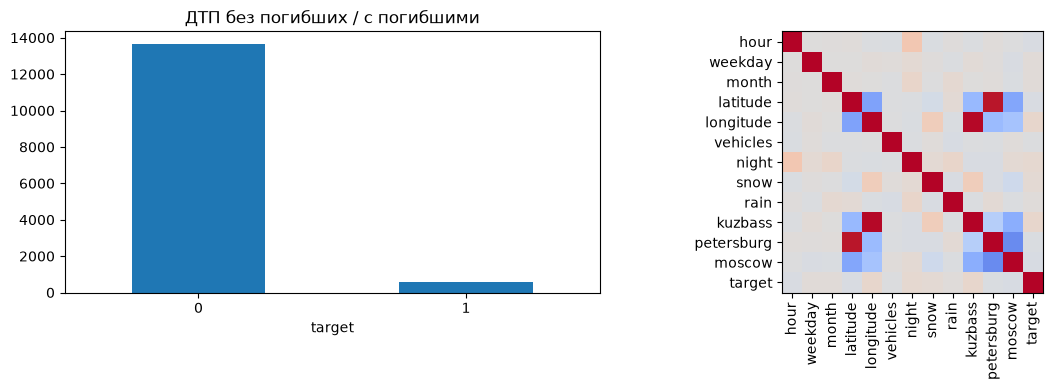

In [2]:
raw, frame, (train, valid, test) = prepare(WORK)
display(pd.DataFrame([{'выборка': name, 'ДТП': len(part), 'с погибшими': int(part.target.sum()),
                       'доля': part.target.mean()} for name, part in [('train', train), ('valid', valid), ('test', test)]]))
display(raw.isna().mean().rename('доля пропусков').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
frame.target.value_counts().sort_index().plot.bar(ax=axes[0], title='ДТП без погибших / с погибшими', rot=0)
axes[1].imshow(frame[FEATURES + ['target']].corr(), vmin=-1, vmax=1, cmap='coolwarm')
axes[1].set_xticks(range(len(FEATURES)+1), FEATURES+['target'], rotation=90)
axes[1].set_yticks(range(len(FEATURES)+1), FEATURES+['target'])
plt.tight_layout(); plt.show()

## 2. Feature Store

Одинаковую функцию подготовки использую для обучения и записи в Feast.
В offline store лежит Parquet, в online store — SQLite. Ключ — карточка ДТП, время признаков — время события.
Пропуски и диапазоны обрабатываю по заранее заданным правилам, без статистик тестовой выборки.
Проверяю historical retrieval, online retrieval и запрос до появления карточки.

In [3]:
store, refs, feature_checks = feature_store(WORK, frame)
display(pd.Series(feature_checks).to_frame('результат'))
print((WORK / 'feast/feature_store.yaml').read_text(encoding='utf-8'))

Materializing 1 feature views from 2024-12-31 00:10:00+00:00 to 2026-01-01 22:20:00+00:00 into the sqlite online store.

conditions:


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\pipeline.py:80: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  early['event_timestamp'] -= pd.Timedelta(days=1)


,результат
historical_rows,14262
online_rows,100
feature_match,True
future_leakage_test,True


entity_key_serialization_version: 3
offline_store:
  type: file
online_store:
  path: "C:\\Users\\Anton\\Desktop\\projects\\\u0423\u043D\u0438\u043A\\2 \u043A\u0443\
    \u0440\u0441\\\u0421\u043E\u0432\u0440\u0435\u043C\u0435\u043D\u043D\u044B\u0435\
    \ \u0442\u0435\u0445\u043D\u043E\u043B\u043E\u0433\u0438\u0438 \u043E\u0431\u0440\
    \u0430\u0431\u043E\u0442\u043A\u0438 \u0431\u043E\u043B\u044C\u0448\u0438\u0445\
    \ \u0434\u0430\u043D\u043D\u044B\u0445\\big_data\\_work\\lab04\\feast\\online.db"
  type: sqlite
project: dtp_lab4
provider: local
registry: "C:\\Users\\Anton\\Desktop\\projects\\\u0423\u043D\u0438\u043A\\2 \u043A\
  \u0443\u0440\u0441\\\u0421\u043E\u0432\u0440\u0435\u043C\u0435\u043D\u043D\u044B\
  \u0435 \u0442\u0435\u0445\u043D\u043E\u043B\u043E\u0433\u0438\u0438 \u043E\u0431\
  \u0440\u0430\u0431\u043E\u0442\u043A\u0438 \u0431\u043E\u043B\u044C\u0448\u0438\u0445\
  \ \u0434\u0430\u043D\u043D\u044B\u0445\\big_data\\_work\\lab04\\feast\\registry.db"



## 3. MLflow и выбор версии

Сравниваю Dummy, Logistic Regression, Random Forest, градиентный бустинг и GaussianNB.
Отдельно обучаю две приватные версии GaussianNB. Параметры, качество, время и модели сохраняю в MLflow.
Победителя выбираю по validation PR-AUC. Перед назначением alias `production` проверяю итоговое качество
против константного baseline и p95 инференса < 50 мс. Это gate для этого опыта; AUC 0.85 из примера fraud detection сюда не переношу.

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\mlflow\store\tracking\sqlalchemy_store.py:356: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1)
  sqlalchemy.orm.configure_mappers()


2026/11/14 13:52:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/14 13:52:37 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
2026/11/14 13:52:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/14 13:52:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/14 13:52:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (9 outputs left out)


Registered model 'DTPSeverity' already exists. Creating a new version of this model...
Created version '6' of model 'DTPSeverity'.


Registered model 'DTPSeverity' already exists. Creating a new version of this model...
Created version '7' of model 'DTPSeverity'.


,model,auc,pr_auc,f1,accuracy,fit_seconds
2,forest,0.674477,0.117869,0.000000,0.952296,0.454262
3,boosting,0.629810,0.117744,0.042553,0.951578,0.100731
4,naive_bayes,0.674834,0.101333,0.158940,0.908895,0.002947
1,logistic,0.659485,0.097343,0.000000,0.952296,0.014274
6,private_eps2,0.638156,0.088378,0.128686,0.883429,0.009074
5,private_eps1,0.617988,0.082785,0.127090,0.906385,0.008918
0,dummy,0.500000,0.047704,0.000000,0.952296,0.001488


,результат
winner,forest
version,6
tracking_uri,sqlite:///C:/Users/Anton/Desktop/projects/Уник...
test,"{'auc': 0.648114232133943, 'pr_auc': 0.1031386..."
latency,"{'p50_ms': 3.1229999985953327, 'p95_ms': 4.149..."
privacy_budget,"[3, 0.0]"
gate,True
candidate_name,boosting
candidate_version,7


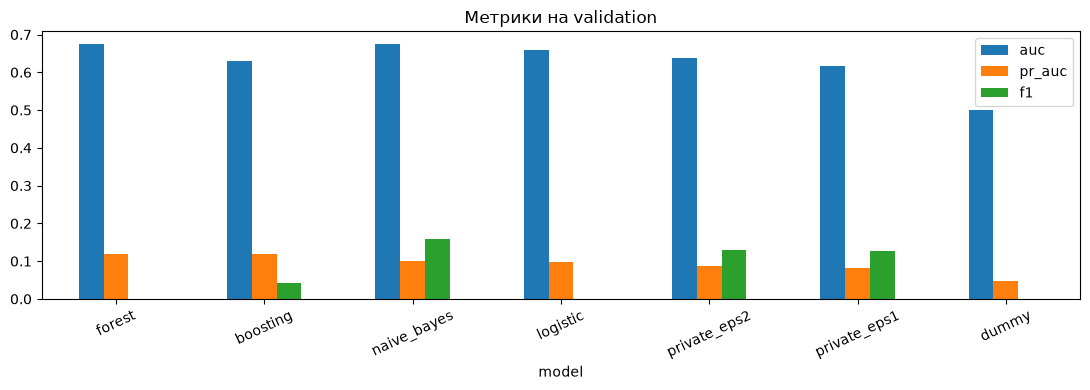

MLflow backend: sqlite:///C:/Users/Anton/Desktop/projects/Уник/2 курс/Современные технологии обработки больших данных/big_data/_work/lab04/mlflow.db


In [4]:
models, production_model, comparison, model_info = fit_models(WORK, train, valid, test)
display(comparison)
display(pd.Series(model_info).to_frame('результат'))
comparison.set_index('model')[['auc', 'pr_auc', 'f1']].plot.bar(figsize=(11, 4), title='Метрики на validation', rot=25)
plt.tight_layout(); plt.show()
print('MLflow backend:', mlflow.get_tracking_uri())

У редкого класса порог 0.5 может вообще не давать положительных решений. Поэтому сервис возвращает вероятность,
а не обещание, что погибшие обязательно будут или не будут. При выборе порога нужно отдельно учитывать цену пропуска.
Сохранённую версию загрузил через Model Registry и сверил её прогноз с исходной моделью.

## 4. REST-инференс, canary и откат

FastAPI получает ID карточки, достаёт признаки из Feast и возвращает вероятность.
Для canary использую 5% ключей запроса; в shadow новая модель считает прогноз для всех запросов.
Проверяю 200 запросов с четырьмя одновременными клиентами, неизвестный ID и некорректное тело запроса.
Отдельно измеряю чистый инференс модели и полный HTTP-запрос с Feature Store.

In [5]:
candidate_model = mlflow.sklearn.load_model('models:/DTPSeverity@candidate')
http_metrics = test_service(WORK, store, refs, production_model, model_info['version'],
                            candidate_model, valid, test, model_info['candidate_version'])
display(pd.Series({k:v for k,v in http_metrics.items() if k != 'metrics'}).to_frame('результат'))
display(pd.DataFrame(http_metrics['metrics']['deployments']))
assert http_metrics['rollback_checked'] and http_metrics['load_errors'] == 0

,результат
p50_ms,45.96955
p95_ms,57.19467
p99_ms,109.199733
throughput_rps,82.991512
canary_requests,9
shadow_requests,200
candidate_promoted,True
rollback_checked,True
expected_error_cases,4
boundaries_checked,True


,event,version,percent,pr_auc,baseline_pr_auc,p95_ms
0,canary_started,7,5.0,NaN,NaN,NaN
1,promoted,7,NaN,0.117744,0.117869,2.883895
2,canary_started,bad-candidate,5.0,NaN,NaN,NaN
3,rolled_back,bad-candidate,NaN,0.047704,0.117744,0.030005


В canary подаю другую зарегистрированную модель из сравнения и проверяю её на validation.
Затем подаю константную модель: проверка качества должна отклонить её и вернуть предыдущую версию.
Сбои 404/422 считаю отдельно от ошибок нагрузочного прогона.

## 5. Мониторинг и переобучение

Считаю PSI и KS по признакам, отдельно проверяю пропуски и диапазоны.
Признак считаю изменившимся при PSI > 0.2; доля таких признаков > 0.3 вызывает переобучение.
Проверяю контрольную выборку, реальные изменения между сезонами и искусственный сдвиг.
Второй опыт — падение accuracy после подмены меток; ADWIN отдельно проверяю на смене потока ошибок.
Алерт отправляю на локальный HTTP-webhook, чтобы проверить доставку без сообщений в чужие чаты.

In [6]:
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
import threading
received_alerts = []
class AlertReceiver(BaseHTTPRequestHandler):
    def do_POST(self):
        received_alerts.append(json.loads(self.rfile.read(int(self.headers['Content-Length']))))
        self.send_response(200); self.end_headers()
    def log_message(self, *args): pass
alert_server = ThreadingHTTPServer(('127.0.0.1', 0), AlertReceiver)
alert_thread = threading.Thread(target=alert_server.serve_forever, daemon=True)
alert_thread.start()
try:
    monitoring, real_drift = monitor(WORK, train, valid, test, production_model,
                                    webhook=f'http://127.0.0.1:{alert_server.server_port}')
finally:
    alert_server.shutdown(); alert_server.server_close(); alert_thread.join()
assert len(received_alerts) == 1
display(pd.Series(monitoring).to_frame('результат'))
display(real_drift)
print('Полученный webhook:', received_alerts)

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
2026/11/14 13:53:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/14 13:53:03 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


,результат
control_score,0.0
injected_score,0.5
real_score,0.166667
accuracy_drop_injected,0.904591
adwin_checked,True
retrain_rows,11050
retrain_accepted,False
prediction_shift,"{'feature': 'hour', 'psi': 0.01746580023670668..."


,feature,psi,ks,missing,out_of_range
0,hour,0.032386,0.037201,0.0,0
1,weekday,0.002513,0.007858,0.0,0
2,month,25.703949,1.000000,0.0,0
3,latitude,0.002296,0.018881,0.0,0
4,longitude,0.000833,0.030144,0.0,0
5,vehicles,0.043366,0.093038,0.0,0
6,night,0.365938,0.293063,0.0,0
7,snow,0.067625,0.051891,0.0,0
8,rain,0.008383,0.019919,0.0,0
9,kuzbass,0.000066,0.002977,0.0,0


Полученный webhook: [{'text': 'Проверка: обнаружен сдвиг признаков и падение качества'}]


После триггера обучаю новую Logistic Regression на доступных размеченных данных и проверяю её на отдельном
последнем участке validation. Итоговый test в переобучение не включаю. Новую модель сохраняю в MLflow;
проверка качества может её отклонить. Также проверяю еженедельный триггер переобучения. Сезонный сдвиг признаков сам по себе не означает ухудшение качества.

## 6. Пакетное и онлайн-обучение

Batch-модель переобучаю каждый день на всей доступной истории. Замороженную августовскую модель оставляю третьим baseline. River получает события в порядке времени: сначала прогноз,
затем после завершения дня — метки и обновление. Сравниваю обе модели на одном ноябрьско-декабрьском test.
График по дням показывает онлайн-оценку до обновления, а не качество на уже выученных метках.
Это воспроизведение исторического потока, не ожидание суток в реальном времени.

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\pipeline.py:228: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  next_day = valid[(valid.event_timestamp.dt.floor('D') == day + pd.Timedelta(days=1))]
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\pipeline.py:231: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  after24 = {'day': str(day + pd.Timedelta(days=1)), 'online_pr_auc': float(average_precision_score(next_day.target, next_p)),


2026/11/14 13:53:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/14 13:53:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/11/14 13:53:40 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


2026/11/14 13:53:40 INFO mlflow.pyfunc: Inferring model signature from input example


2026/11/14 13:53:42 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


... (2 outputs left out)

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\pandas\plotting\_matplotlib\converter.py:1087: MatplotlibDeprecationWarning: The locs attribute was deprecated in Matplotlib 3.11 and will be removed in 3.13.
  self.locs = locs


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\pandas\plotting\_matplotlib\converter.py:1087: MatplotlibDeprecationWarning: The locs attribute was deprecated in Matplotlib 3.11 and will be removed in 3.13.
  self.locs = locs


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\pandas\plotting\_matplotlib\converter.py:1087: MatplotlibDeprecationWarning: The locs attribute was deprecated in Matplotlib 3.11 and will be removed in 3.13.
  self.locs = locs
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04-venv\Lib\site-packages\pandas\plotting\_matplotlib\converter.py:1087: MatplotlibDeprecationWarning: The locs attribute was deprecated in Matplotlib 3.11 and will be removed in 3.13.
  self.locs = locs


После первых суток обновлений: {
  "day": "2025-09-02 00:00:00+00:00",
  "online_pr_auc": 0.06066176470588235,
  "frozen_batch_pr_auc": 0.1736111111111111,
  "evaluated_before_labels": true
}


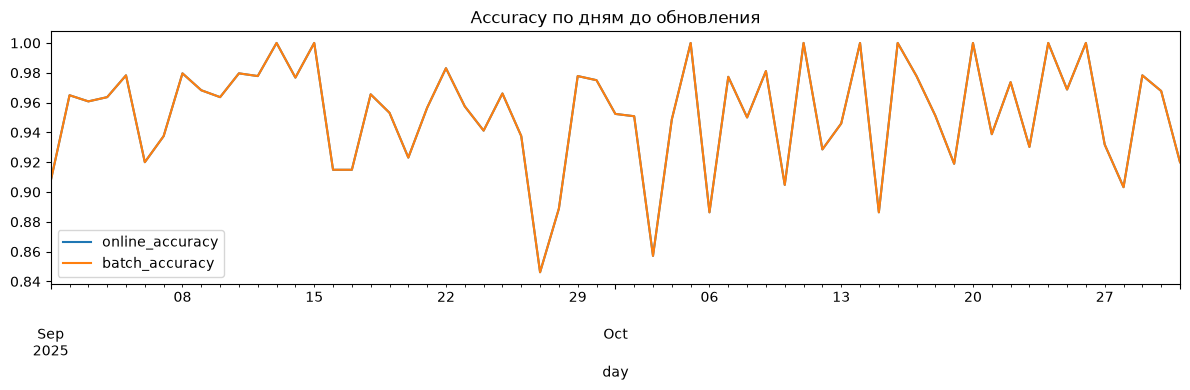

Обновления и время обработки показаны в таблице; обе стратегии в первых двух строках видят одинаковые метки до ноября.


In [7]:
strategies, daily, online_model = compare_online(WORK, train, valid, test, production_model)
display(strategies)
print('После первых суток обновлений:', (WORK/'after24h.json').read_text(encoding='utf-8'))
daily.set_index('day')[['online_accuracy','batch_accuracy']].plot(figsize=(12,4), title='Accuracy по дням до обновления')
plt.tight_layout(); plt.show()
print('Обновления и время обработки показаны в таблице; обе стратегии в первых двух строках видят одинаковые метки до ноября.')

## 7. Дифференциальная приватность

Для варианта 4 использую GaussianNB из diffprivlib. До обучения привожу признаки к публично заданным границам [0,1].
Классы фиксирую заранее: 0 и 1. Приватные модели расходуют epsilon=1 и epsilon=2, delta=0;
общий бюджет двух публикаций — epsilon=3. Соседние наборы отличаются одной карточкой ДТП, не всей историей человека.

Гарантия относится к параметрам этих двух моделей. Обычные модели, исходные данные и весь эксперимент целиком
не становятся приватными. Для примера входа MLflow сохраняю искусственные нули, а не реальные карточки.
Шум не фиксирую seed: при повторном запуске приватные метрики могут измениться. Каждый повтор — новый расход бюджета.

In [8]:
privacy_table = comparison[comparison.model.isin(['naive_bayes','private_eps1','private_eps2'])].copy()
privacy_table['p95_ms'] = [model_latency(models[name], test[FEATURES].head(1))['p95_ms'] for name in privacy_table.model]
display(privacy_table)
baseline_pr = float(comparison.set_index('model').loc['naive_bayes','pr_auc'])
impact = float(comparison.set_index('model').loc['private_eps1','pr_auc'] - baseline_pr)
print('Изменение validation PR-AUC при epsilon=1:', impact)
print('Общий бюджет:', model_info['privacy_budget'])

,model,auc,pr_auc,f1,accuracy,fit_seconds,p95_ms
4,naive_bayes,0.674834,0.101333,0.158940,0.908895,0.002947,0.741050
6,private_eps2,0.638156,0.088378,0.128686,0.883429,0.009074,0.728065
5,private_eps1,0.617988,0.082785,0.127090,0.906385,0.008918,0.986625


Изменение validation PR-AUC при epsilon=1: -0.018548437082106795
Общий бюджет: [3, 0.0]


## 8. Температурный сенсор и автоотключение

Беру ряд NAB из задания. В файле есть многодневные пропуски: не заполняю их будущими значениями
и исключаю окна без полной истории 48 ч и факта на следующие 24 ч.
Обучаю LightGBM до 1 декабря 2013. Для прямого прогноза строю отдельные модели на каждый горизонт,
для рекурсивного — возвращаю точечный прогноз в историю. Сравниваю MAE, MASE и pinball loss для q=0.9.

Пороги выбираю на первой аварии и периоде до марта 2014: цена пропуска=100, ложного отключения=10,
сброса нагрузки=3, уведомления=1. Это условные единицы затрат для сравнения настроек.
Вторую аварию открываю только после сохранения выбранных параметров.

Условие тревоги: риск превышения порога, подтверждение CUSUM, несколько последовательных нарушений и отсутствие cooldown.
Из медианы и q=0.9 приближаю распределение нормальным; максимум вероятностей по шагам — нижняя граница
риска хотя бы одного превышения. Рекурсивную полосу расширяю как sqrt(h), поэтому отдельно измеряю её pinball loss.
Это приближения, а не доказанная калибровка вероятности отказа.

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:48: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  available = x.notna().all(axis=1) & target.notna() & (x.index + pd.Timedelta(hours=horizon - 1) < '2013-12-01')


C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:63: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  dates = origins + pd.Timedelta(hours=h)
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:63: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  dates = origins + pd.Timedelta(hours=h)
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:63: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This incl

... (2 outputs left out)

C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:92: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  if i and now - origins[i - 1] > pd.Timedelta(hours=1):
C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\lab_04\sensor.py:92: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  if i and now - origins[i - 1] > pd.Timedelta(hours=1):


,выбрано до скрытой аварии
strategy,direct
critical,76.670258
p_star,0.8
k,2
cooldown,12
cusum_limit,2.0
cost,1.02


,strategy,precision,recall,false_per_day,false_alarms,missed_failures,lead_hours,alarms
0,direct,0.0,0.0,0.0,0,1,[None],0
1,recursive,0.0,0.0,0.0,0,1,[None],0


,mae,mase,pinball_90
strategy,,,
direct,1.940532,1.241020,0.471951
recursive,2.348514,1.501934,0.811407


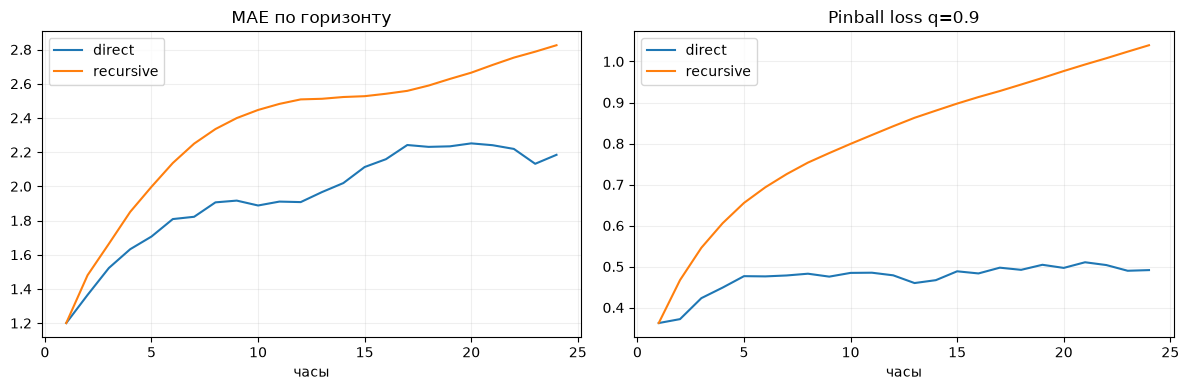

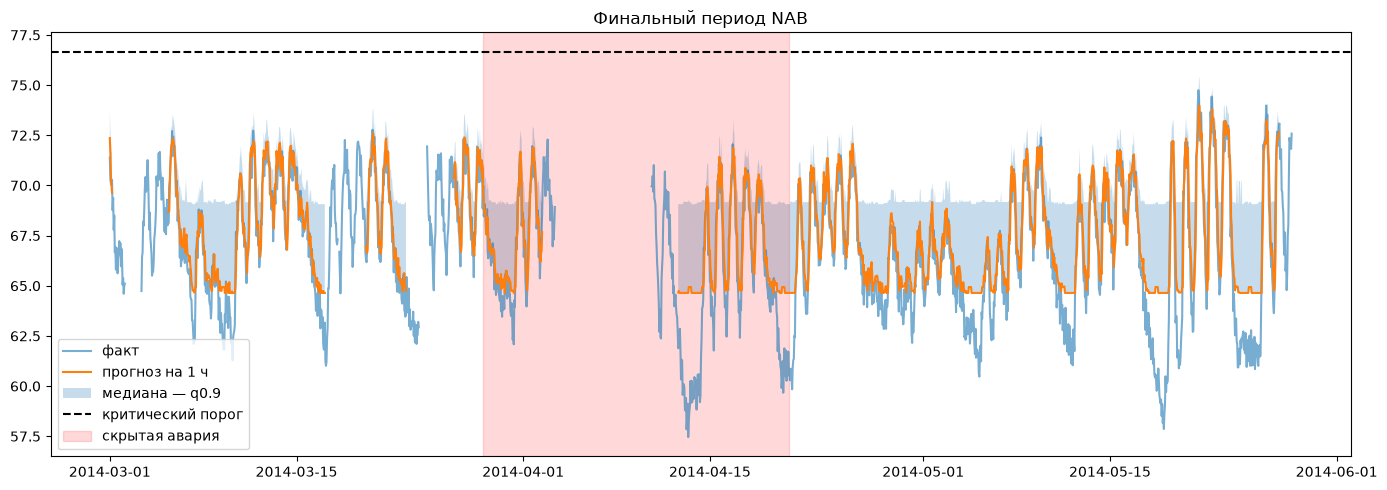

Журнал срабатываний: C:\Users\Anton\Desktop\projects\Уник\2 курс\Современные технологии обработки больших данных\big_data\_work\lab04\sensor_alarm_log.json


""


In [9]:
sensor = experiment(WORK, Path(os.environ.get('DTP_DATA_DIR', str(ROOT / 'data'))))
print('Исходных строк:', sensor['raw_rows'], 'Пропущенных часов:', sensor['missing_hours'])
display(pd.Series(sensor['settings']).to_frame('выбрано до скрытой аварии'))
display(sensor['warning_metrics'])
display(sensor['forecast_metrics'].groupby('strategy')[['mae','mase','pinball_90']].mean())
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, part in sensor['forecast_metrics'].groupby('strategy'):
    axes[0].plot(part.horizon, part.mae, label=name)
    axes[1].plot(part.horizon, part.pinball_90, label=name)
axes[0].set(title='MAE по горизонту', xlabel='часы'); axes[1].set(title='Pinball loss q=0.9', xlabel='часы')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
origins = sensor['origins']; dates = sensor['values'].index
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(sensor['values'].loc['2014-03-01':], label='факт', alpha=.6)
fc = sensor['forecasts']['direct']; mask = origins >= '2014-03-01'
plot_index = sensor['values'].loc['2014-03-01':].index
median = pd.Series(fc[.5][mask,0],index=origins[mask]).reindex(plot_index)
upper = pd.Series(fc[.9][mask,0],index=origins[mask]).reindex(plot_index)
ax.plot(plot_index,median,label='прогноз на 1 ч')
ax.fill_between(plot_index,median,upper,alpha=.25,label='медиана — q0.9')
ax.axhline(sensor['settings']['critical'],color='black',linestyle='--',label='критический порог')
for start,end in sensor['hidden_event']: ax.axvspan(start,end,color='red',alpha=.15,label='скрытая авария')
ax.legend(); ax.set_title('Финальный период NAB'); plt.tight_layout(); plt.show()
print('Журнал срабатываний:', WORK / 'sensor_alarm_log.json')
display(pd.DataFrame([{'strategy': name, **event} for name, events in sensor['logs'].items() for event in events]))

На скрытой аварии правило может не сработать: отдельно показываю пропуски и ложные тревоги, без point-adjustment F1.
Lead time считаю от первого срабатывания до начала аварии; отрицательное значение означает запоздалую тревогу,
а отсутствие срабатывания — пропущенный отказ. Precision считаю по тревогам, recall — по авариям, допуск 24 ч.
Ложные тревоги в день делю на фактическое время наблюдения после исключения пропусков.

## MLflow UI

Сохранил эксперимент и версии моделей из MLflow. При повторном запуске номера версий увеличиваются.

![Эксперимент](evidence/mlflow-experiment.jpg)

![Model Registry](evidence/mlflow-registry.jpg)


## Итоги

Собрал обучение и REST-инференс с одинаковыми признаками Feast, сохранил версии моделей в MLflow.
Проверил shadow, canary и откат при ухудшении качества. Для редкого исхода сравниваю PR-AUC с константной моделью,
а не только accuracy. Приватная модель даёт отдельный компромисс между бюджетом и качеством.
В опыте с сенсором оцениваю прогноз и предупреждения раздельно: меньшая MAE ещё не означает обнаружение аварии.

In [10]:
feature_match_passed = feature_checks['feature_match']
data_drift_score = monitoring['control_score']
inference_latency = model_info['latency']['p95_ms']
online_batch_diff = float(strategies.iloc[1].pr_auc - strategies.iloc[0].pr_auc)
assert feature_match_passed and data_drift_score < .3 and inference_latency < 50
print('## METRICS ##')
print(f'FEATURE_MATCH_TEST_PASSED={feature_match_passed}')
print(f'DATA_DRIFT_SCORE={data_drift_score:.4f}')
print(f'INFERENCE_LATENCY_MS={inference_latency:.2f}')
print(f'ONLINE_BATCH_DIFFERENCE={online_batch_diff:.4f}')
print(f'UNIQUE_REQUIREMENT_IMPACT={impact:.4f}')
(WORK/'summary.json').write_text(json.dumps({'model':model_info,'http':http_metrics,'monitoring':monitoring,
    'sensor_warnings':sensor['warning_metrics'].to_dict('records')},ensure_ascii=False,indent=2),encoding='utf-8')

## METRICS ##
FEATURE_MATCH_TEST_PASSED=True
DATA_DRIFT_SCORE=0.0000
INFERENCE_LATENCY_MS=4.15
ONLINE_BATCH_DIFFERENCE=-0.0451
UNIQUE_REQUIREMENT_IMPACT=-0.0185


2732